**1. Импорт таблицы**

In [64]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = BASE / "data" / "samples"

In [66]:
df = pd.read_csv(DATA / "data_ai_assistant.csv", sep=';', low_memory=False)
df.head()

,request_id,instruction,intent,category,tags,response,property_type,property_id,has_typos,needs_escalation,...,source_label_method,additional_labels_method,annotation_status,weak_label_confidence,noise_type,scenario_group_id,policy_context,is_synthetic,property_assignment_method,category_ru
0,bitext_00001,"Чёрт возьми, не нахожу выставленные счета, пом...",invoices,BILLING,BCEIQWZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,missing_letter,bitext__invoices__29,unspecified,1,source_hospitality_hotel_only,счета
1,bitext_00002,"Не нахожу выставленные счета, помогите. Где мн...",invoices,BILLING,BCIPQZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,transposed_letters,bitext__invoices__29,unspecified,1,source_hospitality_hotel_only,счета
2,bitext_00003,Как скачать счета из личноо кабинета? Объяснит...,invoices,BILLING,BCILPQZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,missing_letter,bitext__invoices__44,unspecified,1,source_hospitality_hotel_only,счета
3,bitext_00004,"Да что же это таке, подскажите, как получить к...",invoices,BILLING,BCIPWZ,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,1,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,missing_letter,bitext__invoices__67,unspecified,1,source_hospitality_hotel_only,счета
4,bitext_00005,"Не нахожу выставленные счета, помогите. Что дл...",invoices,BILLING,BCILM,Счета и чеки обычно доступны в личном кабинете...,hotel,NaN,0,0,...,source_intent,weak_rules_without_property_policies,requires_manual_review,0.35,none,bitext__invoices__29,unspecified,1,source_hospitality_hotel_only,счета


**2. Основная информация**

*Описание датасета:*
- Датасет: data_ai_assistant.csv
- Тип: гибридный
- Количество объектов/строк: 35000
- Количество признаков/столбцов: 27

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   request_id                  35000 non-null  str    
 1   instruction                 35000 non-null  str    
 2   intent                      35000 non-null  str    
 3   category                    35000 non-null  str    
 4   tags                        35000 non-null  str    
 5   response                    35000 non-null  str    
 6   property_type               35000 non-null  str    
 7   property_id                 0 non-null      float64
 8   has_typos                   35000 non-null  int64  
 9   needs_escalation            35000 non-null  int64  
 10  priority                    35000 non-null  str    
 11  language                    35000 non-null  str    
 12  source_dataset              35000 non-null  str    
 13  source_row_id               25000 non-null

*Описание полей:*
- **request_id** (`str`) — уникальный id записи вида bitext_N, где N = 00001..35000
- **instruction** (`str`) — текст обращения гостя на русском (после перевода)
- **intent** (`str`) — тип обращения, класс намерения; целевая метка классификатора
- **category** (`str`) — укрупнённая категория, группа интентов (грубее, чем intent)
- **tags** (`str`) — теги записи
- **response** (`str`) — ответ бота на это обращение (эталонный или сгенерированный)
- **property_type** (`str`) — тип объекта: apartment / hotel / guesthouse
- **has_typos** (`int64`) — бинарный флаг: есть ли в тексте опечатки (0/1)
- **needs_escalation** (`int64`) — целевая метка: 0 — бот отвечает сам, 1 — требуется человек
- **priority** (`str`) — приоритет обращения 
- **language** (`str`) — язык обращения (ожидается `ru` во всех строках)
- **source_dataset** (`str`) — исходный датасет, откуда взята строка
- **source_row_id** (`float64`) — id строки в исходном датасете; заполнено 25 000 из 35 000, `float64` — некорректный тип для идентификатора
- **original_instruction_en** (`str`) — исходный текст на английском до перевода; заполнено 25 000
- **original_response_en** (`str`) — исходный ответ на английском до перевода; заполнено 25 000
- **is_synthetic** (`int64`) — бинарный флаг: 1 — строка синтетическая, 0 — из реального источника

**Вывод:** Практически по всем столбцам полное заполнение для всех 35000 строк. 
Исключения: столбцы source_row_id, original_instruction_en, original_response_en, где заполнены 25000 строк. Это наши дополнительно добавленные 10000 строк сразу на русском языке.

**3. Анализ признаков**

**Текстовые признаки**

In [68]:
str_values = ['request_id', 'instruction', 'response']
for column in str_values:
    is_not_empty = df[column].astype(str).str.strip() != ''
    print(f"Количество корректных (заполненных) строк '{column}': {is_not_empty.sum()} из {df.shape[0]}")

Количество корректных (заполненных) строк 'request_id': 35000 из 35000
Количество корректных (заполненных) строк 'instruction': 35000 из 35000
Количество корректных (заполненных) строк 'response': 35000 из 35000


*Вывод:* Текстовые поля 'request_id', 'instruction', 'response' не содержат пропусков или пустых значений.
<br>
<br>
<br>

**Категориальные признаки**

- *Тип недвижимости 'property_type'*

Возможные значения:

In [69]:
df['property_type'].unique()

<StringArray>
['hotel', 'apartment', 'guesthouse']
Length: 3, dtype: str

Сумма по группам:

In [70]:
print("сумма групп:", df.groupby("property_type").size().sum())
vc = df["property_type"].value_counts()
pd.DataFrame({
    "кол-во, шт": vc,
    "доля, %": (vc / vc.sum() * 100).round(1),
})

сумма групп: 35000


,"кол-во, шт","доля, %"
property_type,,
hotel,28430,81.2
guesthouse,3484,10.0
apartment,3086,8.8


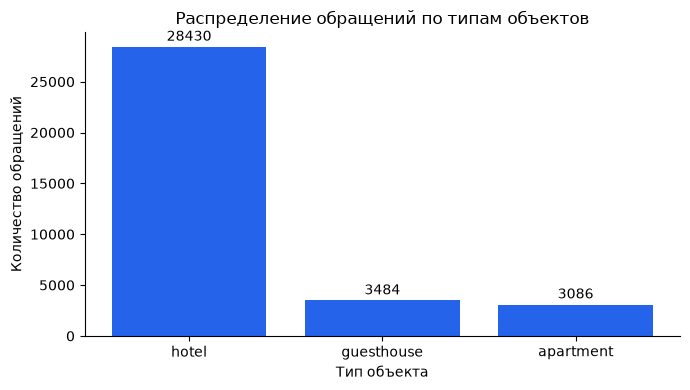

In [71]:
counts = df["property_type"].value_counts()   # уже отсортировано по убыванию

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color="#2563EB")
ax.bar_label(bars, fmt="%d", padding=2)        # числа над столбиками

ax.set_title("Распределение обращений по типам объектов")
ax.set_xlabel("Тип объекта")
ax.set_ylabel("Количество обращений")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Доля исходных обращений для разных типов недвижимости:

In [72]:
g = df.groupby("property_type")["original_instruction_en"].agg(
    total="size",
    is_origin="count",
)
g["is_added"] = g["total"] - g["is_origin"]
print(g)

               total  is_origin  is_added
property_type                            
apartment       3086          0      3086
guesthouse      3484          0      3484
hotel          28430      25000      3430


*Вывод:* Имеется три типа недвижимости 'hotel', 'apartment', 'guesthouse'. Мы видим,  что 81% обращений относятся к отелям, что не отражает реальную структуру рынка краткосрочной аренды, а является следствием формирования датасета, который изначально формировался под отели и куда мы искусственно добавили дополнительные обращения для всех 3 типов недвижимости. Способ устранения дисбаланса рассмотрим на этапе обучения.
<br>
<br>

- *Категории 'category' и интенты 'intent'*

Все возможные значения категорий:

In [73]:
df['category'].unique()

<StringArray>
[          'BILLING', 'CANCELLATION_FEES',          'CHECK_IN',
         'CHECK_OUT',           'CONTACT',             'EVENT',
          'FEEDBACK',             'HOTEL',           'LUGGAGE',
              'MENU',             'NIGHT',     'PARKING_SPACE',
              'PETS',            'POINTS',            'REFUND',
   'SHUTTLE_SERVICE',    'GUEST_SERVICES',           'BOOKING',
       'MAINTENANCE',         'COMPLAINT',         'DEPARTURE',
       'HOUSE_RULES',           'ARRIVAL',        'FACILITIES',
      'HOUSEKEEPING',            'ACCESS',            'SAFETY',
       'LOCAL_GUIDE',     'ACCESSIBILITY']
Length: 29, dtype: str

<br>
Все возможные значения интентов:

In [74]:
df['intent'].unique()

<StringArray>
[                'invoices',        'cancellation_fees',
                 'check_in',                'check_out',
         'customer_service',              'human_agent',
               'host_event',           'file_complaint',
             'leave_review',               'book_hotel',
 'cancel_hotel_reservation', 'change_hotel_reservation',
   'check_hotel_facilities',       'check_hotel_offers',
       'check_hotel_prices',  'check_hotel_reservation',
             'search_hotel',            'store_luggage',
               'check_menu',                'add_night',
       'book_parking_space',               'bring_pets',
            'redeem_points',               'get_refund',
          'shuttle_service',            'lost_property',
             'extra_guests',             'wifi_problem',
          'noise_complaint',             'power_outage',
   'late_check_out_request',           'pest_complaint',
            'visitor_rules', 'air_conditioning_problem',
   'early_check_i

<br>
Интенты, сгруппированные по категориям, в порядке убывания:

In [75]:
categorized_total = 0
for cat in df["category"].value_counts().index:
    g = df[df["category"] == cat]
    print(f"\n{cat}  ({len(g)}, {len(g)/len(df):.2%})")
    for intent, n in g["intent"].value_counts().items():
        categorized_total += n
        print(f"   {intent:26s} {n:5d}")
print(f"\nВсего строк с корректными интентами/категориями: {categorized_total}")


HOTEL  (8969, 25.63%)
   check_hotel_facilities      1136
   check_hotel_offers          1126
   check_hotel_prices          1126
   change_hotel_reservation    1122
   cancel_hotel_reservation    1120
   search_hotel                1120
   book_hotel                  1110
   check_hotel_reservation     1109

CONTACT  (2259, 6.45%)
   customer_service            1131
   human_agent                 1128

FEEDBACK  (2214, 6.33%)
   file_complaint              1109
   leave_review                1105

PARKING_SPACE  (1509, 4.31%)
   book_parking_space          1114
   parking_problem              198
   parking_information          197

BILLING  (1324, 3.78%)
   invoices                    1125
   billing_dispute              199

MAINTENANCE  (1283, 3.67%)
   access_problem               204
   air_conditioning_problem     197
   appliance_problem            194
   wifi_problem                 193
   water_problem                191
   heating_problem              176
   power_outage   

In [76]:
chk = df.groupby("intent", dropna=False)["category"].agg(
    строк="size",
    категорий=lambda s: s.dropna().astype(str).str.strip().replace("", pd.NA).dropna().nunique(),
    какие=lambda s: ", ".join(sorted(s.dropna().astype(str).str.strip().unique())),
)
chk = chk.sort_values("категорий", ascending=False)

print(chk)
print()
print("интентов без категории      :", (chk["категорий"] == 0).sum())
print("интентов с >1 категорией    :", (chk["категорий"] > 1).sum())
print("строк с пустой категорией   :",
      df["category"].isna().sum() + (df["category"].astype(str).str.strip() == "").sum())

                        строк  категорий        какие
intent                                               
access_problem            204          1  MAINTENANCE
pet_issue                 182          1    COMPLAINT
kitchen_usage             188          1   FACILITIES
late_check_out_request    199          1    DEPARTURE
laundry_information       196          1   FACILITIES
...                       ...        ...          ...
early_check_in_request    173          1      ARRIVAL
extra_guests              201          1      BOOKING
file_complaint           1109          1     FEEDBACK
get_refund               1113          1       REFUND
wifi_problem              193          1  MAINTENANCE

[63 rows x 3 columns]

интентов без категории      : 0
интентов с >1 категорией    : 0
строк с пустой категорией   : 0


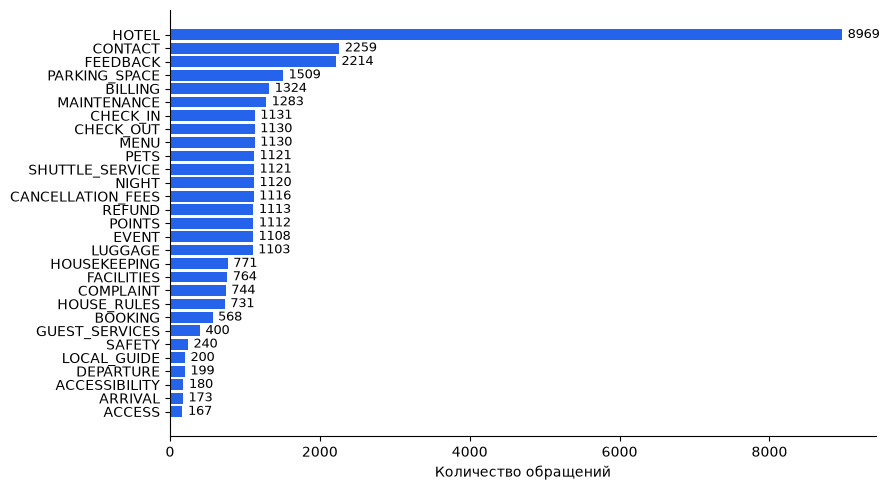

In [77]:
cat = df["category"].value_counts()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(cat.index[::-1], cat.values[::-1], color="#2563EB")

ax.bar_label(bars, fmt="%d", padding=4, fontsize=9)
ax.set_xlabel("Количество обращений")
ax.set_ylabel("")
ax.tick_params(labelsize=10)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

Самые популярные категории обращений по типам проживания:

In [78]:
for prop, sub in df.groupby("property_type", dropna=False):
    vc = sub["category"].value_counts(normalize=True).mul(100)
    t = (vc.head(3).to_frame("доля, %").assign(шт=sub["category"].value_counts().head(3)))
    print(f"\n{prop}  ({len(sub)} строк)")
    print(t.round(1).to_string())
    print()


apartment  (3086 строк)
             доля, %   шт
category                 
MAINTENANCE     13.5  416
HOTEL           10.4  321
FACILITIES       9.1  282


guesthouse  (3484 строк)
             доля, %   шт
category                 
MAINTENANCE     12.5  436
HOTEL            9.1  316
FACILITIES       8.0  277


hotel  (28430 строк)
          доля, %    шт
category               
HOTEL        29.3  8332
CONTACT       7.3  2071
FEEDBACK      7.3  2064



Доля категории HOTEL для всех обращений:

In [79]:
n = (df["category"].astype(str).str.strip().str.lower() == "hotel").sum()
print(f"{n:,} из {len(df):,} = {n / len(df):.1%}")

8,969 из 35,000 = 25.6%


*Вывод:* После проверки столбцов 'category', 'intent' мы видим, что данные корректные. Нет интентов без категории и нет пустых категорий, значения присутствуют в каждой строке. Можно заметить, что обращения с категорией Hotel самые многочисленные в целом (25.6%) и в категории отелей (29%). Лидерство категории объясняется двумя причинами: составом выборки (81% записей — отели) и устойчивой связью темы с типом объекта.
<br>
<br>

- *Приоритет обращения 'priority'*

Возможные значения:

In [80]:
df['priority'].unique()

<StringArray>
['low', 'medium', 'high', 'critical']
Length: 4, dtype: str

In [81]:
df["priority"].value_counts(dropna=False)

priority
low         23435
medium       9313
high         1965
critical      287
Name: count, dtype: int64

Категории с самой большой долей обращений с приоритетом Critical:

In [82]:
raw = pd.crosstab(df["category"], df["priority"]).reindex(columns=["critical"], fill_value=0)
keep = raw["critical"] > 0

c = pd.crosstab(df["category"], df["priority"], normalize="index").mul(100).round(1)
print(c.loc[keep, ["critical"]].sort_values("critical", ascending=False))

priority     critical
category             
SAFETY           96.2
MAINTENANCE       4.4


Доля обращений с приоритетом critical среди интентов по убыванию:

In [83]:
t = pd.crosstab(df["intent"], df["priority"])
t["всего"] = t.sum(axis=1)
t["critical, %"] = (t["critical"] / t["всего"] * 100).round(1)
print(
    t[t["critical"] > 0]  
    .sort_values("critical, %", ascending=False)[["critical", "всего", "critical, %"]]
    .to_string()
)

priority           critical  всего  critical, %
intent                                         
medical_emergency       107    107        100.0
safety_incident         124    133         93.2
power_outage             56    128         43.8


Распределение приоритетов среди категорий:

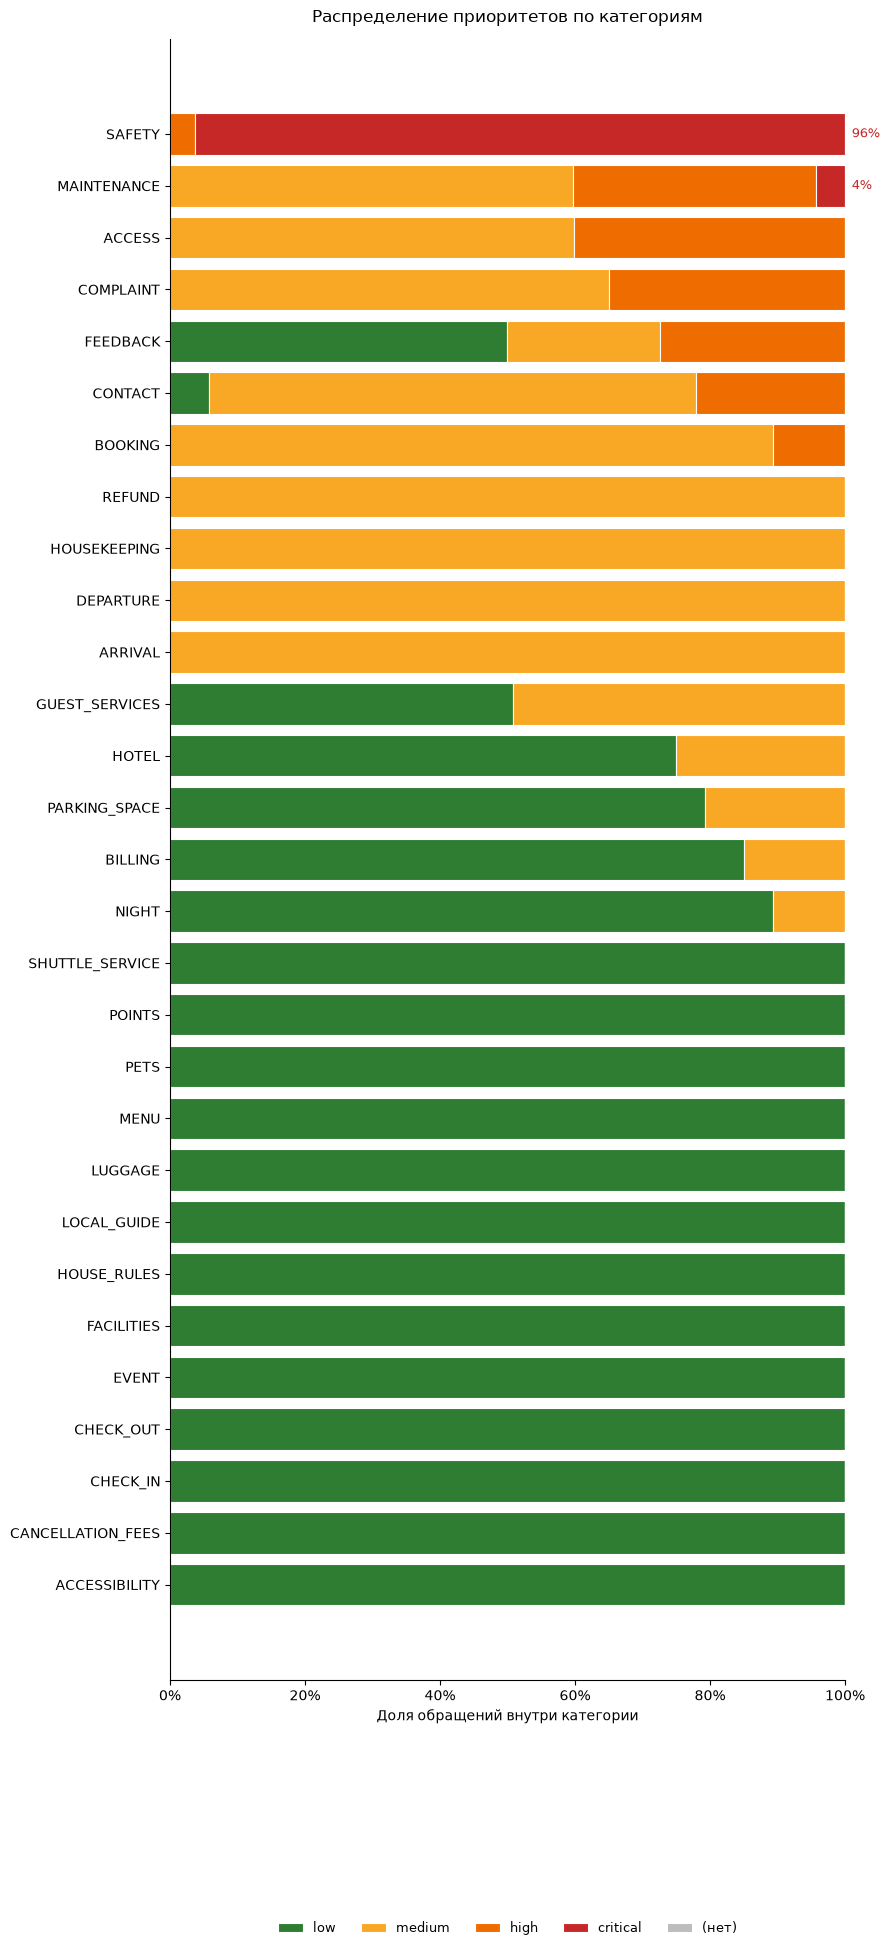

In [84]:
order  = ["low", "medium", "high", "critical", "(нет)"]
colors = {"low":      "#2E7D32",
          "medium":   "#F9A825",
          "high":     "#EF6C00",
          "critical": "#C62828",
          "(нет)":    "#BDBDBD"}

sub = df.copy()
sub["priority"] = sub["priority"].fillna("(нет)")

share = pd.crosstab(sub["category"], sub["priority"]).reindex(columns=order, fill_value=0)
share = share.div(share.sum(axis=1), axis=0)

share = share.sort_values(
    ["critical", "high", "medium", "low", "(нет)"],
    ascending=[True, True, True, True, False],
)

fig, ax = plt.subplots(figsize=(9, 0.6 * len(share) + 2))
left = np.zeros(len(share))

for p in order:
    ax.barh(share.index, share[p], left=left, color=colors[p],
            label=p, edgecolor="white", linewidth=0.8)
    left += share[p].values

for y, v in enumerate(share["critical"]):
    if v > 0:
        ax.text(1.01, y, f"{v:.0%}", va="center", fontsize=9, color=colors["critical"])

ax.set_xlim(0, 1)
ax.set_xlabel("Доля обращений внутри категории")
ax.set_title("Распределение приоритетов по категориям", pad=12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.tick_params(labelsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          frameon=False, fontsize=9)

plt.tight_layout()
plt.show()

*Вывод:* Столбец 'priority' содержит 4 значения приоритетов обращений от critical к low. Основная масса обращений имеет самый низкий приоритет. Так же определены категории, где высокая доля обращений с самым высоким приоритетом, это SAFETY (Безопасность) и MAINTENANCE (Обслуживание). В интентах категории SAFETY доля critical обращений стремится к 100%.
На графике можно увидеть распределение приоритетов внутри категорий. Мы видим, что вопросы безопасности, обслуживания, доступа, жалобы имеют высокий приоритет, в то время как вопросы, касающиеся стандартных тем типа заселения, багажа, а так же дополнительные услуги типа меню, размещения с питомцами имеют низкий приоритет.
<br>
<br>

**Бинарные признаки**

- *Наличие опечаток 'has_typos'*
- *Целевая переменная: Решение об эскалации 'needs_escalation'*

In [85]:
bins = ["has_typos", "needs_escalation"]

for c in bins:
    vc = df[c].value_counts(dropna=False)
    print(f"{c:18s} {vc.to_dict()}   доля 1: {df[c].mean():.1%}")

has_typos          {0: 21836, 1: 13164}   доля 1: 37.6%
needs_escalation   {1: 18446, 0: 16554}   доля 1: 52.7%


*Вывод:* Столбцы 'has_typos' и 'needs_escalation' принимают значения 0 и 1. Пустых значений нет, так же нет некорректных значений. Баланс нормальный. По балансу можно сделать вывод, что доля эскалаций больше половины, а значит продукт смог бы сэнонмить владельцу всего половину работы.

**Выводы:**

**1. Данные.** 35 000 записей: 25 000 переведены с английского, 10 000 изначально на русском. Пропусков и пустых значений в содержательных колонках нет, дубликатов не обнаружено. Происхождение каждой записи зафиксировано, что позволяет считать метрики раздельно.

**2. Типы объектов.** 81% записей — отели, по 9–10% квартиры и гостевые дома. Это следствие формирования датасета, а не структуры рынка краткосрочной аренды. Отсюда два обязательных решения: стратификация train/test по типу объекта и раздельные метрики по каждому типу.

**3. Метки корректны.** У каждого интента ровно одна категория, пустых значений нет. Категория `HOTEL` лидирует по двум причинам: отелей численно больше, и внутри отелей эта тема тоже доминирует — то есть её популярность не объясняется только размером группы.

**4. Приоритеты осмысленны.** Четыре уровня от `low` до `critical`, шкала используется полностью. `critical` сосредоточен в категориях `SAFETY` и `MAINTENANCE`, спокойные темы (заселение, багаж, доп. услуги) высокого приоритета не получают — это соответствует политике.

**5. Эскалация — главная проблема продукта.** Метка сбалансирована (52/48), но 52% эскалаций означают, что консьерж закрывает меньше половины обращений. Целевой уровень для такого продукта — 15–25%. Нужна ревизия разметки: вероятно, часть обращений с ответом в базе знаний помечена как требующая человека.